# Lab 1B: Batch Audio Processing - Multiple Files

Process multiple audio files from a folder and extract basic properties.

In [1]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load Multiple Audio Files

In [2]:
# Specify folder path containing audio files
audio_folder = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/marsyas-dataset/mix"  # CHANGE THIS

# Supported audio formats
audio_extensions = ['.wav', '.mp3', '.flac', '.ogg', '.m4a']

# Get all audio files
audio_files = []
for ext in audio_extensions:
    audio_files.extend(Path(audio_folder).glob(f'*{ext}'))
    audio_files.extend(Path(audio_folder).glob(f'*{ext.upper()}'))

audio_files = sorted(list(set(audio_files)))  # Remove duplicates and sort

print(f"Found {len(audio_files)} audio files")
for i, file in enumerate(audio_files[:10], 1):
    print(f"{i}. {file.name}")
if len(audio_files) > 10:
    print(f"... and {len(audio_files) - 10} more files")

Found 10 audio files
1. blues.00000.wav
2. classical.00000.wav
3. country.00000.wav
4. disco.00000.wav
5. hiphop.00000.wav
6. jazz.00000.wav
7. metal.00000.wav
8. pop.00000.wav
9. reggae.00000.wav
10. rock.00000.wav


## 2. Extract Properties from All Files

In [3]:
def extract_audio_properties(file_path):
    """
    Extract basic properties from audio file.
    """
    try:
        # Load audio
        y, sr = librosa.load(file_path, sr=None)
        
        # Calculate properties
        properties = {
            'filename': Path(file_path).name,
            'sample_rate': sr,
            'duration': len(y) / sr,
            'num_samples': len(y),
            'max_amplitude': np.max(np.abs(y)),
            'min_amplitude': np.min(y),
            'mean_amplitude': np.mean(y),
            'std_amplitude': np.std(y),
            'rms': np.sqrt(np.mean(y**2)),
            'is_normalized': np.max(np.abs(y)) <= 1.0
        }
        return properties
    
    except Exception as e:
        print(f"Error processing {Path(file_path).name}: {str(e)}")
        return None

# Process all files
all_properties = []
print("Processing files...")

for i, audio_file in enumerate(audio_files, 1):
    props = extract_audio_properties(audio_file)
    if props:
        all_properties.append(props)
    if i % 10 == 0:
        print(f"Processed {i}/{len(audio_files)} files")

print(f"\nSuccessfully processed {len(all_properties)} files")

Processing files...
Processed 10/10 files

Successfully processed 10 files


## 3. Create DataFrame Summary

In [4]:
# Convert to DataFrame
df = pd.DataFrame(all_properties)

# Display first few rows
print("First 10 files:")
print(df.head(10).to_string())

# Save to CSV
output_csv = "audio_properties.csv"
df.to_csv(output_csv, index=False)
print(f"\nSaved properties to {output_csv}")

First 10 files:
              filename  sample_rate   duration  num_samples  max_amplitude  min_amplitude  mean_amplitude  std_amplitude       rms  is_normalized
0      blues.00000.wav        22050  30.013333       661794       0.885376      -0.840240       -0.000060       0.140688  0.140688           True
1  classical.00000.wav        22050  30.013333       661794       0.343628      -0.343628       -0.000169       0.039174  0.039175           True
2    country.00000.wav        22050  30.081633       663300       0.773529      -0.771118       -0.001348       0.249836  0.249840           True
3      disco.00000.wav        22050  30.121542       664180       0.749176      -0.749176       -0.001564       0.156031  0.156039           True
4     hiphop.00000.wav        22050  30.000181       661504       1.000000      -1.000000       -0.017717       0.133600  0.134769           True
5       jazz.00000.wav        22050  30.013333       661794       0.681976      -0.634735       -0.000947   

## 4. Statistical Summary

In [5]:
print("="*60)
print("STATISTICAL SUMMARY ACROSS ALL FILES")
print("="*60)

print(f"\nTotal Files: {len(df)}")
print(f"\nSample Rates:")
print(df['sample_rate'].value_counts())

print(f"\nDuration Statistics (seconds):")
print(f"  Mean: {df['duration'].mean():.2f}")
print(f"  Median: {df['duration'].median():.2f}")
print(f"  Min: {df['duration'].min():.2f}")
print(f"  Max: {df['duration'].max():.2f}")
print(f"  Total: {df['duration'].sum():.2f}")

print(f"\nAmplitude Statistics:")
print(f"  Max Amplitude Range: [{df['max_amplitude'].min():.4f}, {df['max_amplitude'].max():.4f}]")
print(f"  Mean RMS: {df['rms'].mean():.4f}")
print(f"  Normalized Files: {df['is_normalized'].sum()}/{len(df)}")

print("="*60)

STATISTICAL SUMMARY ACROSS ALL FILES

Total Files: 10

Sample Rates:
22050    10
Name: sample_rate, dtype: int64

Duration Statistics (seconds):
  Mean: 30.03
  Median: 30.01
  Min: 30.00
  Max: 30.12
  Total: 300.27

Amplitude Statistics:
  Max Amplitude Range: [0.3436, 1.0000]
  Mean RMS: 0.1355
  Normalized Files: 10/10


## 5. Visualize Distribution

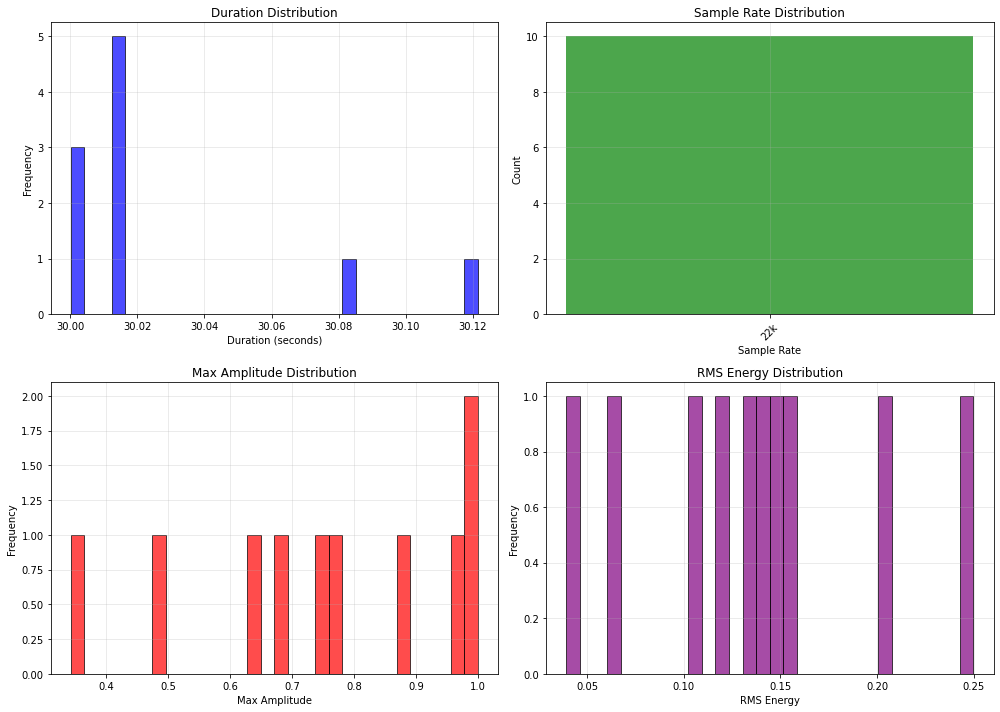

Saved visualization to audio_distribution.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Duration distribution
axes[0, 0].hist(df['duration'], bins=30, color='blue', alpha=0.7, edgecolor='black')
axes[0, 0].set_xlabel('Duration (seconds)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Duration Distribution')
axes[0, 0].grid(True, alpha=0.3)

# Sample rate distribution
sr_counts = df['sample_rate'].value_counts()
axes[0, 1].bar(range(len(sr_counts)), sr_counts.values, color='green', alpha=0.7)
axes[0, 1].set_xticks(range(len(sr_counts)))
axes[0, 1].set_xticklabels([f"{int(sr/1000)}k" for sr in sr_counts.index], rotation=45)
axes[0, 1].set_xlabel('Sample Rate')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title('Sample Rate Distribution')
axes[0, 1].grid(True, alpha=0.3)

# Max amplitude distribution
axes[1, 0].hist(df['max_amplitude'], bins=30, color='red', alpha=0.7, edgecolor='black')
axes[1, 0].set_xlabel('Max Amplitude')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Max Amplitude Distribution')
axes[1, 0].grid(True, alpha=0.3)

# RMS distribution
axes[1, 1].hist(df['rms'], bins=30, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].set_xlabel('RMS Energy')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('RMS Energy Distribution')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/audio_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved visualization to audio_distribution.png")

## 6. Compare Sample Waveforms

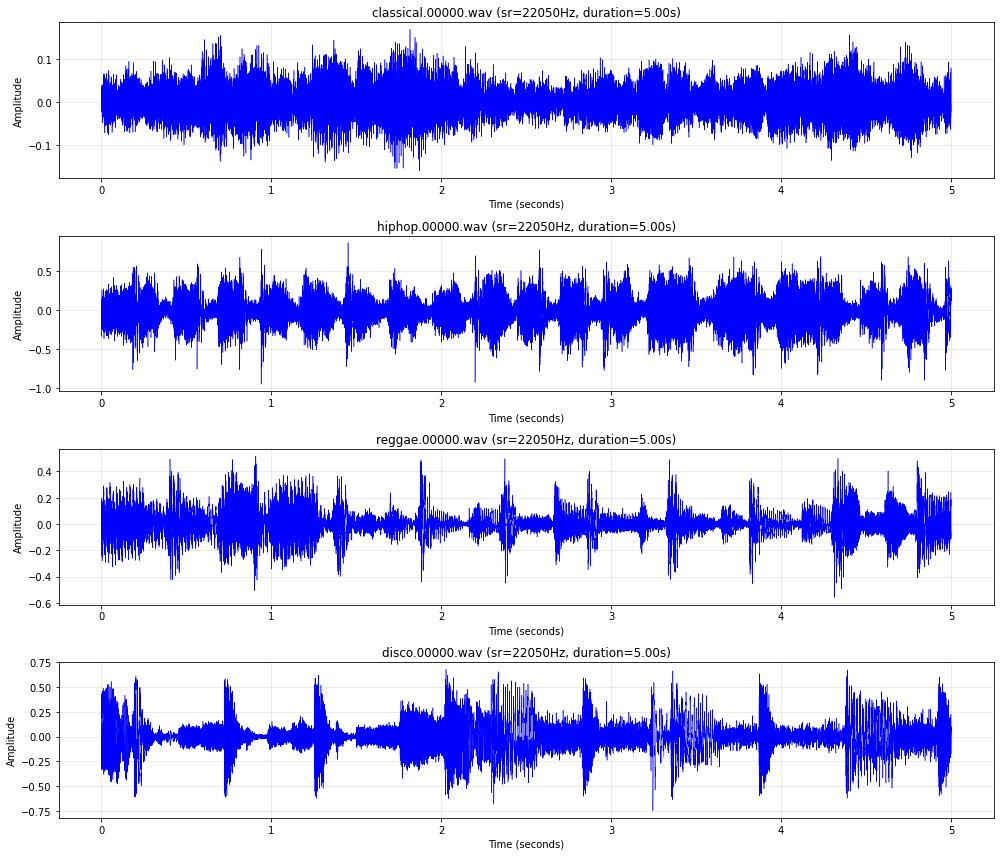

Saved waveforms to sample_waveforms.png


In [7]:
# Select up to 4 random files for comparison
num_samples = min(4, len(audio_files))
sample_files = np.random.choice(audio_files, num_samples, replace=False)

fig, axes = plt.subplots(num_samples, 1, figsize=(14, 3*num_samples))
if num_samples == 1:
    axes = [axes]

for i, audio_file in enumerate(sample_files):
    y, sr = librosa.load(audio_file, sr=None, duration=5)  # Load first 5 seconds
    time = np.linspace(0, len(y)/sr, len(y))
    
    axes[i].plot(time, y, linewidth=0.5, color='blue')
    axes[i].set_xlabel('Time (seconds)')
    axes[i].set_ylabel('Amplitude')
    axes[i].set_title(f"{Path(audio_file).name} (sr={sr}Hz, duration={len(y)/sr:.2f}s)")
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/sample_waveforms.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved waveforms to sample_waveforms.png")

## 7. Filter Files by Criteria

In [8]:
# Filter by sample rate
sr_filter = 22050
filtered_sr = df[df['sample_rate'] == sr_filter]
print(f"Files with sample rate {sr_filter}Hz: {len(filtered_sr)}")

# Filter by duration
min_duration = 2.0  # seconds
max_duration = 10.0
filtered_duration = df[(df['duration'] >= min_duration) & (df['duration'] <= max_duration)]
print(f"Files with duration between {min_duration}s and {max_duration}s: {len(filtered_duration)}")

# Filter by amplitude (normalized)
normalized_files = df[df['is_normalized'] == True]
print(f"Normalized files: {len(normalized_files)}")

# Files that need normalization
unnormalized_files = df[df['is_normalized'] == False]
print(f"Files needing normalization: {len(unnormalized_files)}")
if len(unnormalized_files) > 0:
    print("\nFiles needing normalization:")
    print(unnormalized_files[['filename', 'max_amplitude']].to_string(index=False))

Files with sample rate 22050Hz: 10
Files with duration between 2.0s and 10.0s: 0
Normalized files: 10
Files needing normalization: 0


## 8. Batch Normalize Audio Files

In [9]:
import soundfile as sf

def normalize_and_save(input_path, output_folder):
    """
    Normalize audio file and save to output folder.
    """
    try:
        # Load audio
        y, sr = librosa.load(input_path, sr=None)
        
        # Normalize
        max_amp = np.max(np.abs(y))
        if max_amp > 0:
            y_normalized = y / max_amp
        else:
            y_normalized = y
        
        # Save
        output_path = Path(output_folder) / Path(input_path).name
        sf.write(output_path, y_normalized, sr)
        return True
    except Exception as e:
        print(f"Error normalizing {Path(input_path).name}: {str(e)}")
        return False

# Create output folder
output_folder = "normalized_audio"
os.makedirs(output_folder, exist_ok=True)

# Normalize all files (or just unnormalized ones)
print(f"Normalizing audio files to {output_folder}/")
success_count = 0

for i, audio_file in enumerate(audio_files, 1):
    if normalize_and_save(audio_file, output_folder):
        success_count += 1
    if i % 10 == 0:
        print(f"Processed {i}/{len(audio_files)} files")

print(f"\nSuccessfully normalized {success_count}/{len(audio_files)} files")

Normalizing audio files to normalized_audio/
Processed 10/10 files

Successfully normalized 10/10 files


## 9. Generate Summary Report

In [10]:
# Create comprehensive report
report = []
report.append("="*60)
report.append("AUDIO DATASET SUMMARY REPORT")
report.append("="*60)
report.append(f"\nDataset Location: {audio_folder}")
report.append(f"Total Files: {len(df)}")
report.append(f"Total Duration: {df['duration'].sum():.2f} seconds ({df['duration'].sum()/60:.2f} minutes)")
report.append(f"\nSAMPLE RATES:")
for sr, count in df['sample_rate'].value_counts().items():
    report.append(f"  {int(sr)}Hz: {count} files")
report.append(f"\nDURATION STATISTICS:")
report.append(f"  Mean: {df['duration'].mean():.2f}s")
report.append(f"  Median: {df['duration'].median():.2f}s")
report.append(f"  Range: [{df['duration'].min():.2f}s, {df['duration'].max():.2f}s]")
report.append(f"\nAMPLITUDE STATISTICS:")
report.append(f"  Mean Max Amplitude: {df['max_amplitude'].mean():.4f}")
report.append(f"  Mean RMS: {df['rms'].mean():.4f}")
report.append(f"  Normalized Files: {df['is_normalized'].sum()}/{len(df)}")
report.append("\n" + "="*60)

report_text = "\n".join(report)
print(report_text)

# Save report
with open("audio_dataset_report.txt", "w") as f:
    f.write(report_text)
print("\nSaved report to audio_dataset_report.txt")

AUDIO DATASET SUMMARY REPORT

Dataset Location: /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/marsyas-dataset/mix
Total Files: 10
Total Duration: 300.27 seconds (5.00 minutes)

SAMPLE RATES:
  22050Hz: 10 files

DURATION STATISTICS:
  Mean: 30.03s
  Median: 30.01s
  Range: [30.00s, 30.12s]

AMPLITUDE STATISTICS:
  Mean Max Amplitude: 0.7538
  Mean RMS: 0.1355
  Normalized Files: 10/10


Saved report to audio_dataset_report.txt


## Summary

This notebook processed multiple audio files and:
- Extracted basic properties (sample rate, duration, amplitude)
- Created statistical summaries
- Visualized distributions
- Filtered files by criteria
- Normalized audio files
- Generated comprehensive report

Output files:
- `audio_properties.csv`: Properties for all files
- `audio_distribution.png`: Distribution visualizations
- `sample_waveforms.png`: Sample waveform comparisons
- `audio_dataset_report.txt`: Summary report
- `normalized_audio/`: Normalized audio files